# Análise Exploratória — Dataset NASA C-MAPSS

**Projeto:** Previsão de Vida Útil Remanescente (RUL) em Motores Turbofan  
**Fase:** 01 — EDA  
**Objetivo:** Entender o dataset do ponto de vista do negócio antes de modelar

---

## Contexto de Negócio

Motores turbofan são o coração de aeronaves comerciais. Uma falha não anunciada pode custar:

- **AOG (Aircraft on Ground):** US$ 10.000–150.000/hora em custos diretos + lucro cessante
- **Manutenção corretiva** custa em média 3–5× mais do que manutenção preventiva
- **Descarte prematuro de peças:** trocar componentes antes do necessário desperdiça até 30% da vida útil restante

A **Manutenção Preditiva (PdM)** resolve esse dilema: usar dados de sensores para estimar *quando* o motor vai falhar e planejar a manutenção na janela certa — nem cedo demais, nem tarde demais.

**Nossa pergunta central:** Dado o histórico de leituras de sensores de um motor, quantos ciclos ainda restam até a falha?

> **RUL (Remaining Useful Life):** número de ciclos operacionais que o motor ainda pode completar com segurança antes de precisar de intervenção.

---
## Critérios de Sucesso

Antes de explorar os dados, definimos **o que consideramos um modelo suficientemente bom**. Sem critérios explícitos, qualquer resultado pode parecer aceitável — ou inaceitável.

A literatura de PHM (Prognostics and Health Management) estabelece benchmarks para o C-MAPSS:

| Critério | Threshold aceitável | Referência |
|---|---|---|
| RMSE | < 15 ciclos | Ramasso & Saxena (2014) |
| PHM Score | Menor que o baseline linear | Saxena et al. (2008) |
| Previsões tardias | < 50% do total | Prática operacional |

> **Contexto operacional:** Um ciclo turbofan equivale a aproximadamente **10 horas de voo**. Um RMSE de 15 ciclos representa ~150 horas de incerteza na janela de manutenção — o limite aceitável para planejamento logístico de uma companhia aérea de médio porte.

Esses critérios serão usados como régua de avaliação nos Notebooks 03 e 04.

## Setup

In [1]:
import sys
from pathlib import Path

# Garante que src/ é importável a partir do notebook
PROJECT_ROOT = Path.cwd().parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from src.data.loader import load_cmapss, load_subset_completo
from src.features.piecewise_rul import apply_piecewise_rul
from src.utils.config import (
    COLUNAS_SENSORES,
    COLUNAS_OP_SETTINGS,
    SENSORES_CONSTANTES,
    RUL_CAP,
    SUBSETS,
)

# Estilo visual consistente
sns.set_theme(style="whitegrid", palette="muted", font_scale=1.1)
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (12, 5)

print(f"Raiz do projeto: {PROJECT_ROOT}")
print("Imports OK")

Raiz do projeto: c:\Users\Pichau\Documents\cmapss-rul-prediction
Imports OK


---
## 1. O Dataset: Frota de Motores em Simulação

O **NASA C-MAPSS** (Commercial Modular Aero-Propulsion System Simulation) simula uma frota de motores turbofan rodando até a falha. Cada motor começa com grau de desgaste inicial variável (normal de fabricação) e desenvolve uma falha progressiva ao longo do tempo.

**4 cenários (subsets)** com complexidade crescente:

| Subset | Motores (treino) | Motores (teste) | Condições Operacionais | Modos de Falha |
|--------|-----------------|-----------------|----------------------|----------------|
| FD001  | 100             | 100             | 1 (nível do mar)      | 1 (compressor) |
| FD002  | 260             | 259             | 6                     | 1 (compressor) |
| FD003  | 100             | 100             | 1 (nível do mar)      | 2 (comp. + fan)|
| FD004  | 248             | 249             | 6                     | 2 (comp. + fan)|

> **Interpretação de negócio:** FD001 é o cenário mais controlado (voo doméstico, falha única). FD004 representa uma frota heterogênea operando em múltiplos perfis de missão com dois modos de falha simultâneos — o cenário mais próximo da realidade operacional.

In [2]:
# Carrega treino de todos os subsets
dados = {subset: load_subset_completo(subset) for subset in SUBSETS}

# Visão rápida do volume de dados
resumo_volume = []
for subset, d in dados.items():
    train_df = d["train"]
    test_df = d["test"]
    resumo_volume.append({
        "Subset": subset,
        "Motores treino": train_df["unit_id"].nunique(),
        "Motores teste": test_df["unit_id"].nunique(),
        "Linhas treino": f"{len(train_df):,}",
        "Linhas teste": f"{len(test_df):,}",
        "Sensores": train_df.filter(like="sensor_").shape[1],
        "Op. settings": train_df.filter(like="op_setting_").shape[1],
    })

pd.DataFrame(resumo_volume).set_index("Subset")

,Motores treino,Motores teste,Linhas treino,Linhas teste,Sensores,Op. settings
Subset,,,,,,
FD001,100,100,"20,631","13,096",21,3
FD002,260,259,"53,759","33,991",21,3
FD003,100,100,"24,720","16,596",21,3
FD004,249,248,"61,249","41,214",21,3


## 2. Anatomia de um Motor: Ciclos de Vida

Cada linha do dataset é um **snapshot** de um ciclo operacional. Um motor com 200 ciclos contribui com 200 linhas. Vamos entender como a vida útil se distribui na frota.

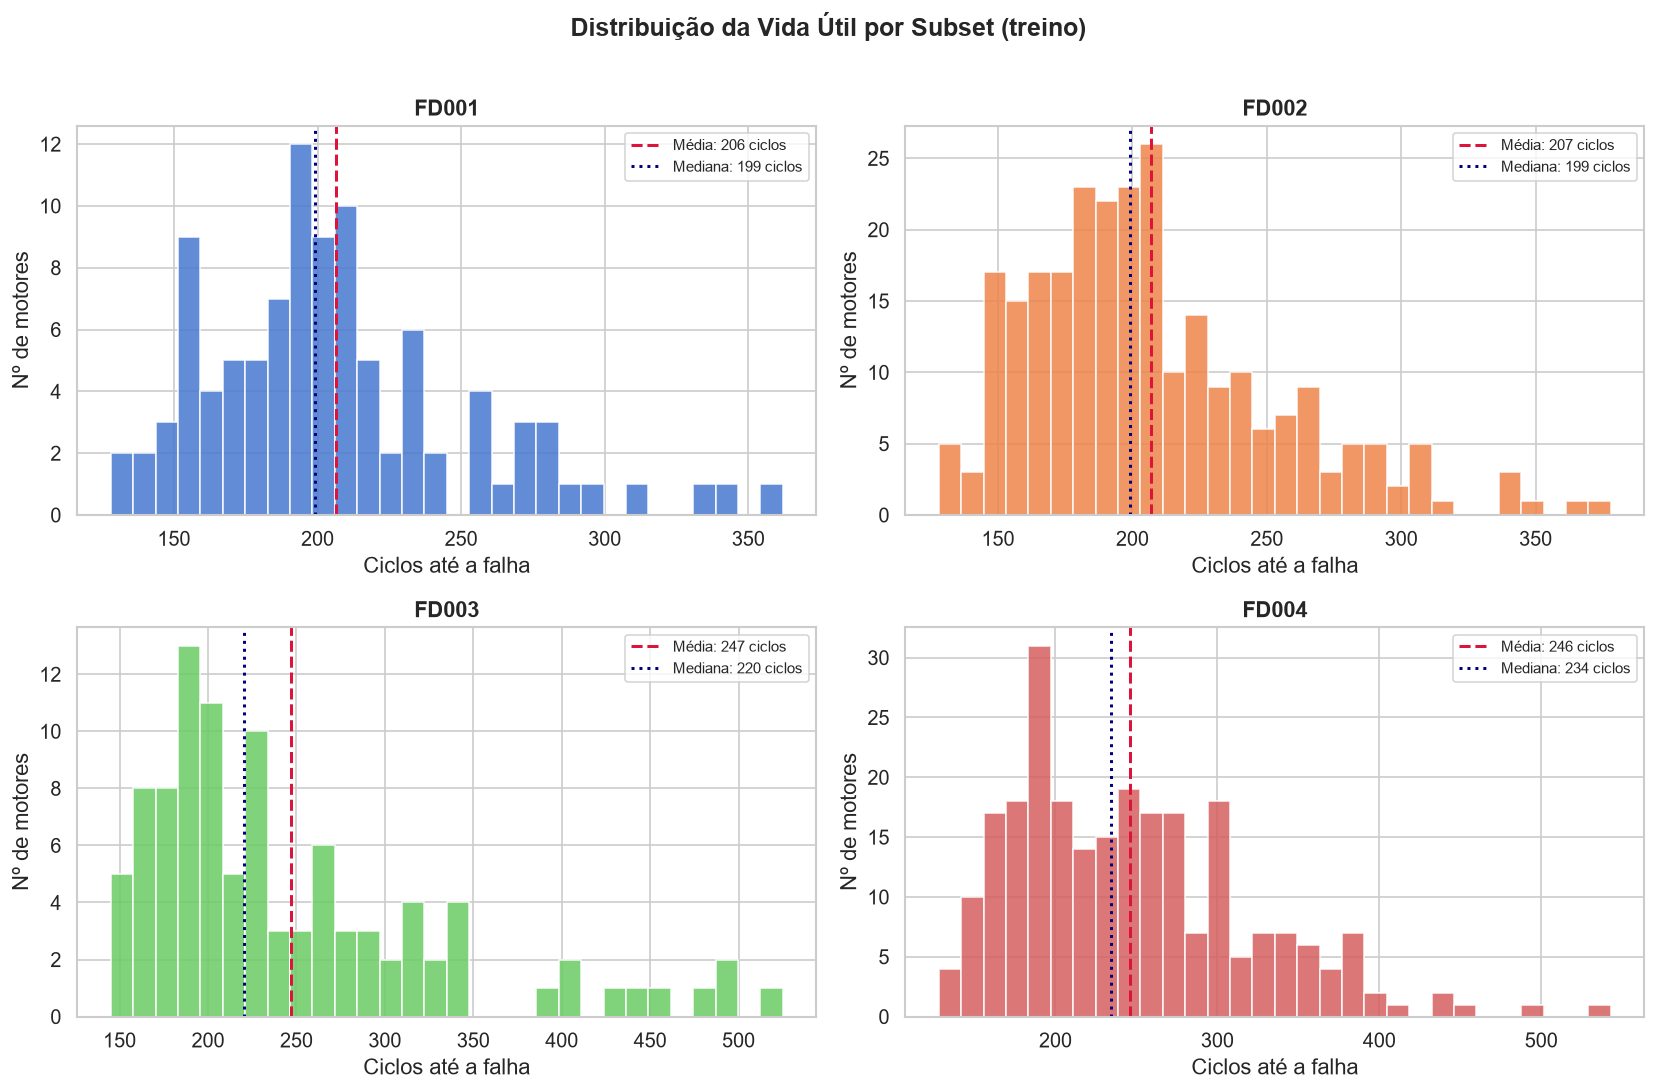

,Mín,Mediana,Média,Máx,Desvio padrão
Subset,,,,,
FD001,128,199.0,206.3,362,46.3
FD002,128,199.0,206.8,378,46.8
FD003,145,220.5,247.2,525,86.5
FD004,128,234.0,246.0,543,73.1


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, subset in enumerate(SUBSETS):
    train_df = dados[subset]["train"]
    vida_util = train_df.groupby("unit_id")["cycle"].max()

    ax = axes[i]
    ax.hist(vida_util, bins=30, color=sns.color_palette("muted")[i], edgecolor="white", alpha=0.85)
    ax.axvline(vida_util.mean(), color="crimson", linestyle="--", lw=1.8, label=f"Média: {vida_util.mean():.0f} ciclos")
    ax.axvline(vida_util.median(), color="navy", linestyle=":", lw=1.8, label=f"Mediana: {vida_util.median():.0f} ciclos")
    ax.set_title(f"{subset}", fontsize=13, fontweight="bold")
    ax.set_xlabel("Ciclos até a falha")
    ax.set_ylabel("Nº de motores")
    ax.legend(fontsize=9)

fig.suptitle("Distribuição da Vida Útil por Subset (treino)", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Tabela resumo
stats_vida = []
for subset in SUBSETS:
    vida = dados[subset]["train"].groupby("unit_id")["cycle"].max()
    stats_vida.append({
        "Subset": subset,
        "Mín": vida.min(),
        "Mediana": vida.median(),
        "Média": round(vida.mean(), 1),
        "Máx": vida.max(),
        "Desvio padrão": round(vida.std(), 1),
    })
pd.DataFrame(stats_vida).set_index("Subset")

> **Insight de negócio:** A variabilidade na vida útil (mín ~130 até máx ~360 ciclos em FD001) reflete o desgaste inicial diferente de cada motor — um desafio real de frota. O modelo precisa aprender a estimar o RUL *relativo* a partir dos sinais de degradação, não a partir da idade absoluta.

## 3. O Target: RUL e o Cap de 125 Ciclos

No conjunto de **treino**, o RUL é calculado como:
$$\text{RUL}_{t} = \text{max\_cycle}_{\text{motor}} - \text{cycle}_{t}$$

Porém, a literatura estabelece um **piecewise cap de 125 ciclos**: nas fases iniciais de vida, os sensores não capturam degradação — o motor opera normalmente. Forçar o modelo a aprender um RUL de 300, 250 ou 200 ciclos a partir de leituras quase idênticas introduz ruído sem ganho preditivo.

**Analogia de negócio:** É como tentar prever a data de validade de um produto novo com base no cheiro — antes de deteriorar, não há sinal. O cap define onde o sinal começa a existir.

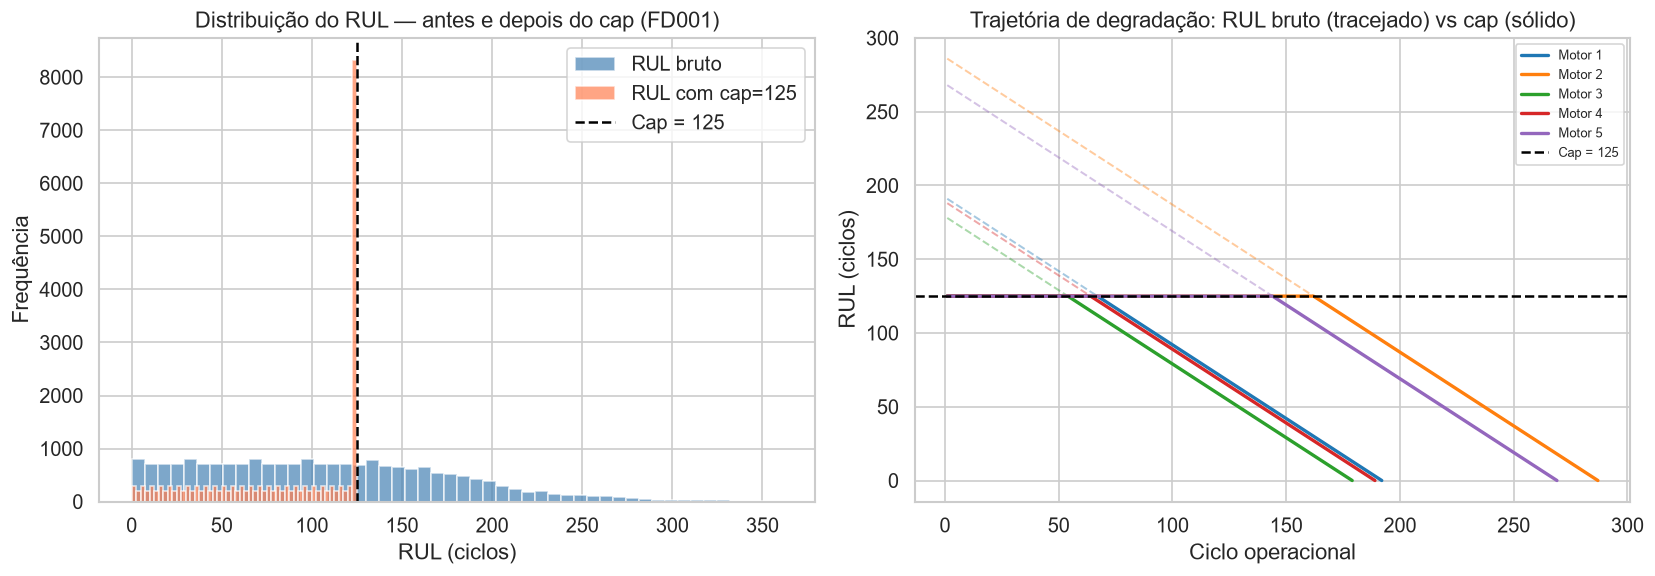

In [4]:
# Visualiza efeito do cap no FD001
train_fd001 = dados["FD001"]["train"].copy()
max_cycle = train_fd001.groupby("unit_id")["cycle"].transform("max")
train_fd001["rul_raw"] = max_cycle - train_fd001["cycle"]
train_fd001["rul_capped"] = apply_piecewise_rul(train_fd001["rul_raw"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Distribuição antes e depois
axes[0].hist(train_fd001["rul_raw"], bins=50, color="steelblue", alpha=0.7, label="RUL bruto", edgecolor="white")
axes[0].hist(train_fd001["rul_capped"], bins=50, color="coral", alpha=0.7, label=f"RUL com cap={RUL_CAP}", edgecolor="white")
axes[0].axvline(RUL_CAP, color="black", linestyle="--", lw=1.5, label=f"Cap = {RUL_CAP}")
axes[0].set_xlabel("RUL (ciclos)")
axes[0].set_ylabel("Frequência")
axes[0].set_title("Distribuição do RUL — antes e depois do cap (FD001)")
axes[0].legend()

# Trajetória de degradação de 5 motores
motores_ex = train_fd001["unit_id"].unique()[:5]
cores = sns.color_palette("tab10", 5)
for j, (motor, cor) in enumerate(zip(motores_ex, cores)):
    sub = train_fd001[train_fd001["unit_id"] == motor]
    axes[1].plot(sub["cycle"], sub["rul_raw"], color=cor, alpha=0.4, lw=1.2, linestyle="--")
    axes[1].plot(sub["cycle"], sub["rul_capped"], color=cor, lw=2, label=f"Motor {motor}")

axes[1].axhline(RUL_CAP, color="black", linestyle="--", lw=1.5, label=f"Cap = {RUL_CAP}")
axes[1].set_xlabel("Ciclo operacional")
axes[1].set_ylabel("RUL (ciclos)")
axes[1].set_title("Trajetória de degradação: RUL bruto (tracejado) vs cap (sólido)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

## 4. Sensores: Quais Carregam Informação?

O dataset tem **21 sensores**. Não todos são úteis — alguns são constantes ao longo de toda a vida do motor (sem variância = sem informação preditiva). A literatura identifica 7 sensores constantes que devem ser removidos antes da modelagem.

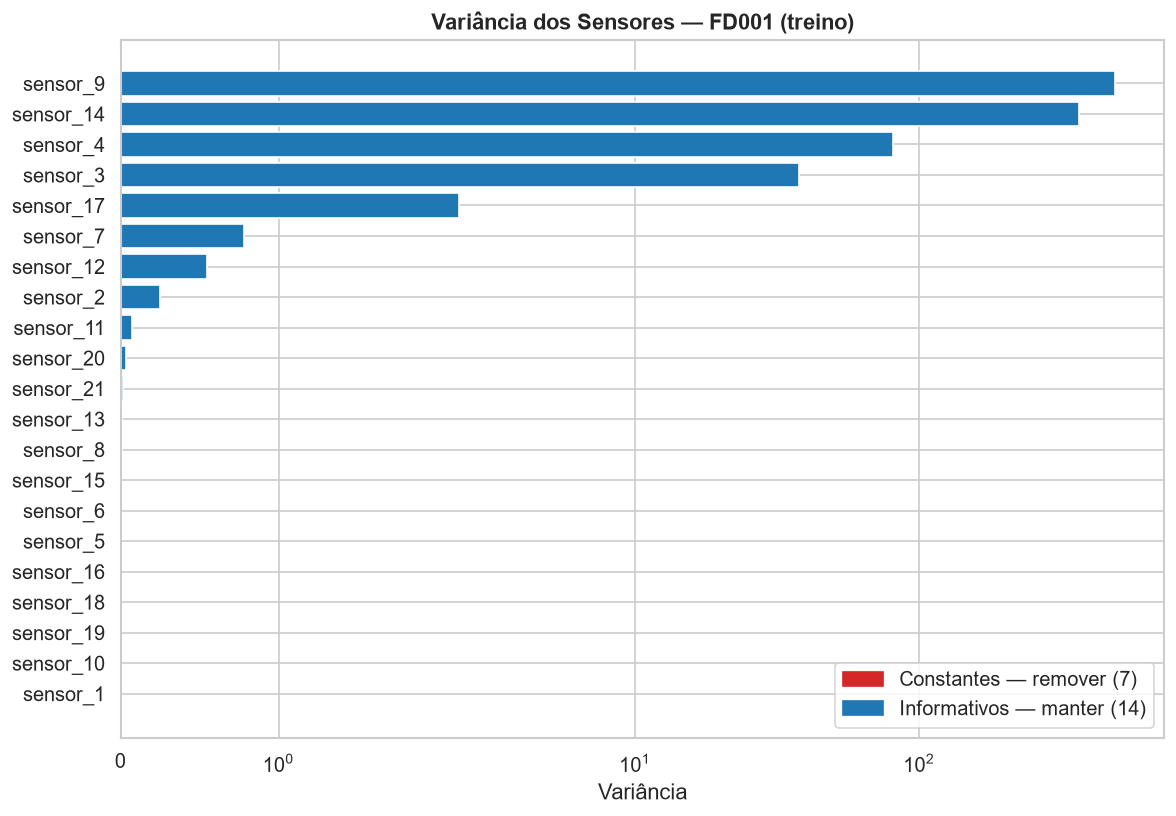

Sensores constantes (remover): ['sensor_1', 'sensor_5', 'sensor_6', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Sensores informativos (manter): ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [5]:
train_fd001 = dados["FD001"]["train"]
sensor_cols = [f"sensor_{i}" for i in range(1, 22)]
constantes_nomes = [f"sensor_{i}" for i in SENSORES_CONSTANTES]
uteis_nomes = [c for c in sensor_cols if c not in constantes_nomes]

# Variância de cada sensor
variancias = train_fd001[sensor_cols].var().sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(10, 7))
cores_barra = ["#d62728" if s in constantes_nomes else "#1f77b4" for s in variancias.index]
bars = ax.barh(variancias.index, variancias.values, color=cores_barra)

from matplotlib.patches import Patch
legenda = [
    Patch(color="#d62728", label=f"Constantes — remover ({len(constantes_nomes)})"),
    Patch(color="#1f77b4", label=f"Informativos — manter ({len(uteis_nomes)})"),
]
ax.legend(handles=legenda, loc="lower right")
ax.set_xlabel("Variância")
ax.set_title("Variância dos Sensores — FD001 (treino)", fontweight="bold")
ax.set_xscale("symlog")
plt.tight_layout()
plt.show()

print(f"Sensores constantes (remover): {constantes_nomes}")
print(f"Sensores informativos (manter): {uteis_nomes}")

## 5. Padrão de Degradação: Como os Sensores Evoluem

A pergunta central da PdM é: **os sensores mudam de forma consistente conforme o motor se aproxima da falha?** Se sim, é possível aprender esse padrão e prever o RUL.

Vamos normalizar os ciclos de 0 (início) a 1 (falha) para comparar motores com diferentes vidas úteis na mesma escala.

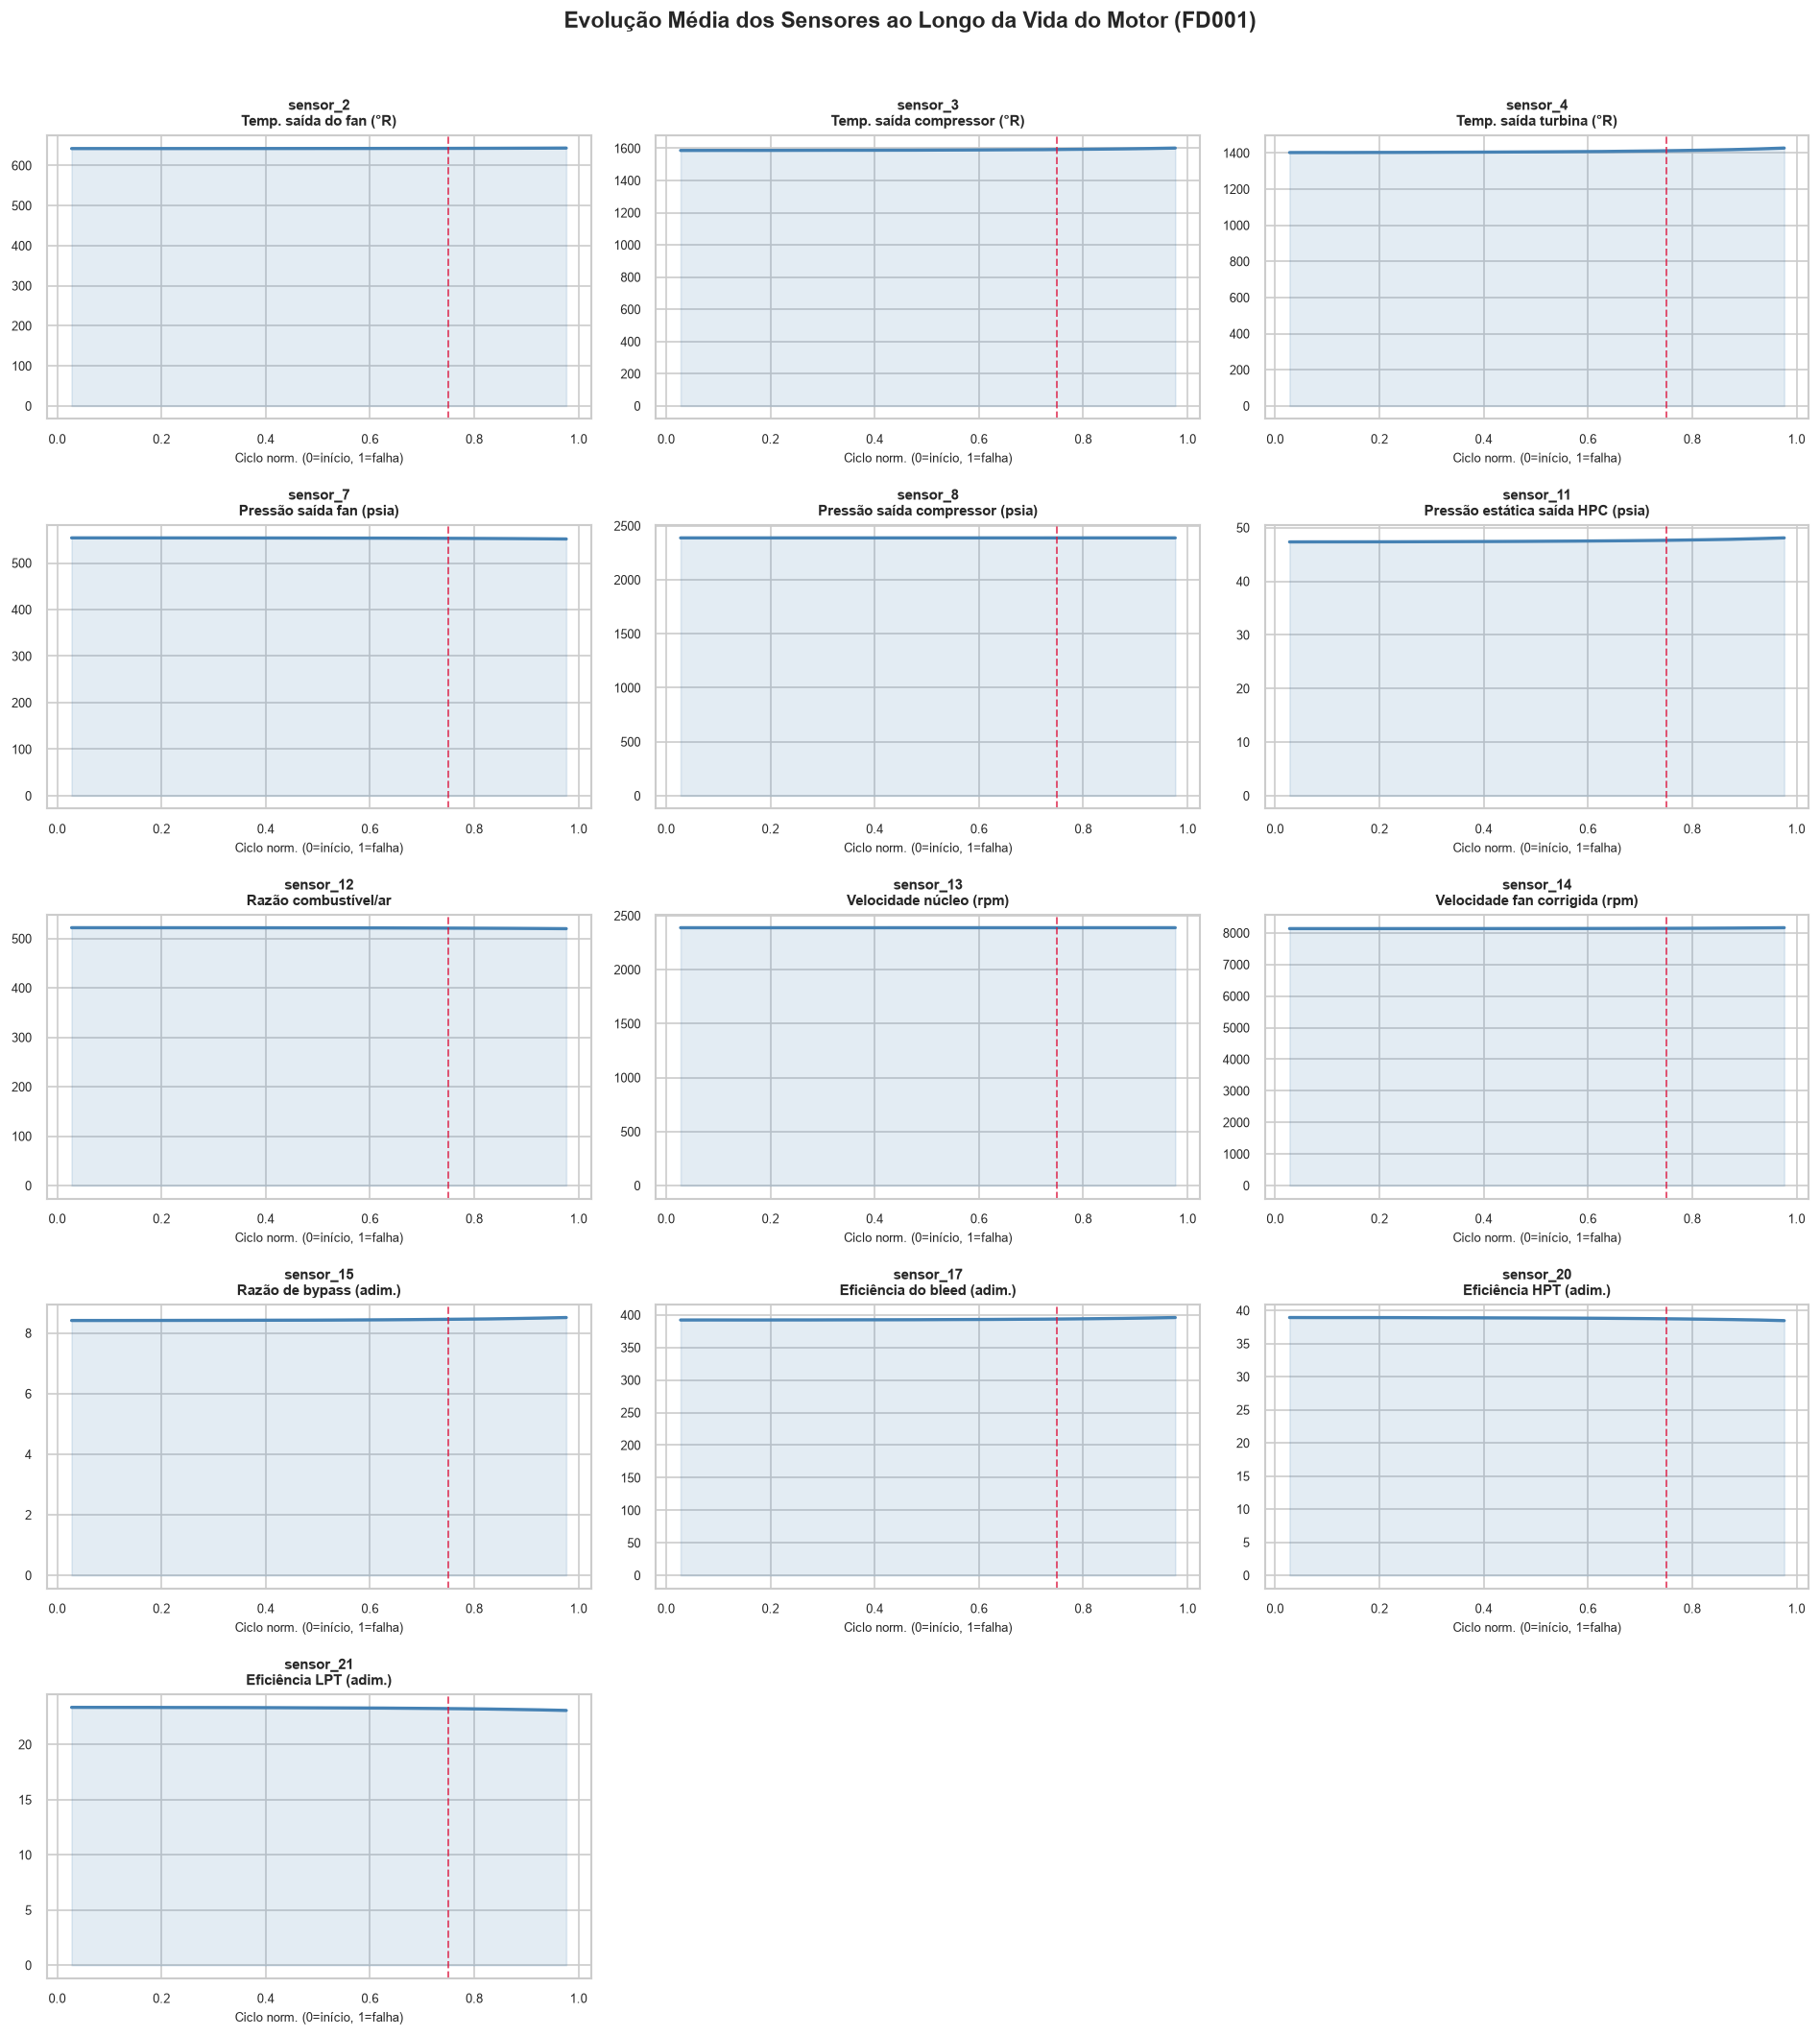

In [6]:
train_fd001 = dados["FD001"]["train"].copy()
max_cycle_map = train_fd001.groupby("unit_id")["cycle"].max()
train_fd001["cycle_norm"] = train_fd001["cycle"] / train_fd001["unit_id"].map(max_cycle_map)

# Sensores informativos para plotar (escolha dos mais interpretáveis)
sensores_plot = ["sensor_2", "sensor_3", "sensor_4", "sensor_7",
                 "sensor_8", "sensor_11", "sensor_12", "sensor_13",
                 "sensor_14", "sensor_15", "sensor_17", "sensor_20", "sensor_21"]

# Descrições físicas dos sensores mais relevantes (Saxena 2008)
descricao_sensor = {
    "sensor_2":  "Temp. saída do fan (°R)",
    "sensor_3":  "Temp. saída compressor (°R)",
    "sensor_4":  "Temp. saída turbina (°R)",
    "sensor_7":  "Pressão saída fan (psia)",
    "sensor_8":  "Pressão saída compressor (psia)",
    "sensor_11": "Pressão estática saída HPC (psia)",
    "sensor_12": "Razão combustível/ar",
    "sensor_13": "Velocidade núcleo (rpm)",
    "sensor_14": "Velocidade fan corrigida (rpm)",
    "sensor_15": "Razão de bypass (adim.)",
    "sensor_17": "Eficiência do bleed (adim.)",
    "sensor_20": "Eficiência HPT (adim.)",
    "sensor_21": "Eficiência LPT (adim.)",
}

# Média dos sensores em bins de ciclo normalizado (suaviza o ruído)
train_fd001["bin_norm"] = pd.cut(train_fd001["cycle_norm"], bins=20, labels=False)
media_bins = train_fd001.groupby("bin_norm")[sensores_plot].mean()
bin_centers = train_fd001.groupby("bin_norm")["cycle_norm"].mean()

n_cols = 3
n_rows = (len(sensores_plot) + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, n_rows * 3.5))
axes = axes.flatten()

for k, sensor in enumerate(sensores_plot):
    ax = axes[k]
    ax.plot(bin_centers.values, media_bins[sensor].values, color="steelblue", lw=2)
    ax.fill_between(bin_centers.values, media_bins[sensor].values,
                    alpha=0.15, color="steelblue")
    ax.axvline(0.75, color="crimson", linestyle="--", lw=1.2, alpha=0.7, label="75% da vida")
    titulo = descricao_sensor.get(sensor, sensor)
    ax.set_title(f"{sensor}\n{titulo}", fontsize=9, fontweight="bold")
    ax.set_xlabel("Ciclo norm. (0=início, 1=falha)", fontsize=8)
    ax.tick_params(labelsize=8)

# Remove eixos vazios
for k in range(len(sensores_plot), len(axes)):
    axes[k].set_visible(False)

fig.suptitle("Evolução Média dos Sensores ao Longo da Vida do Motor (FD001)",
             fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

> **Insight crítico:** Sensores como `sensor_4` (temperatura de saída da turbina) e `sensor_11` (pressão do compressor) mostram tendências monotônicas claras conforme o motor se aproxima da falha. Outros, como `sensor_14` (velocidade do fan corrigida), mostram queda — indicando perda de eficiência. Essa **assinatura de degradação** é o que o modelo vai aprender.

## 6. Ruído vs Sinal: O Desafio dos Dados de Sensor

Dados reais de sensor contêm ruído. Vamos comparar a leitura bruta com a média móvel para entender a relação sinal-ruído — isso justificará as **features de janela deslizante** da fase 02.

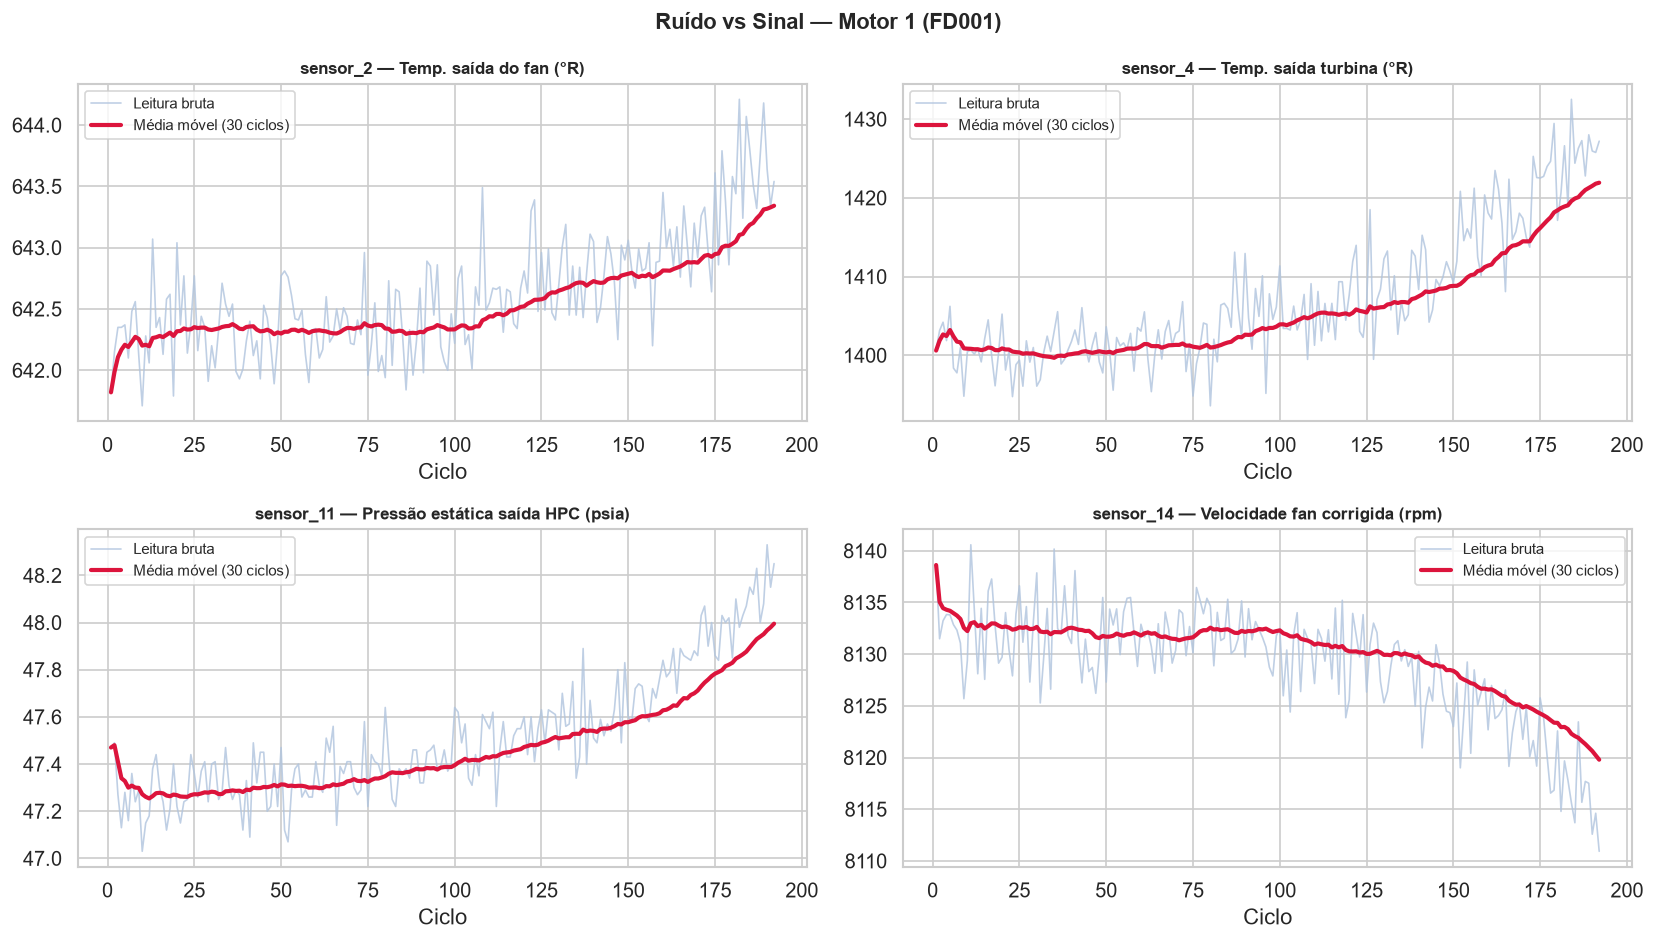

In [7]:
motor_ex = 1
motor_data = dados["FD001"]["train"][dados["FD001"]["train"]["unit_id"] == motor_ex].copy()

sensores_ruido = ["sensor_2", "sensor_4", "sensor_11", "sensor_14"]
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
axes = axes.flatten()

for k, sensor in enumerate(sensores_ruido):
    ax = axes[k]
    ax.plot(motor_data["cycle"], motor_data[sensor],
            color="lightsteelblue", lw=1, alpha=0.8, label="Leitura bruta")
    media_movel = motor_data[sensor].rolling(window=30, min_periods=1).mean()
    ax.plot(motor_data["cycle"], media_movel,
            color="crimson", lw=2.5, label="Média móvel (30 ciclos)")
    ax.set_title(f"{sensor} — {descricao_sensor.get(sensor, '')}", fontsize=10, fontweight="bold")
    ax.set_xlabel("Ciclo")
    ax.legend(fontsize=9)

fig.suptitle(f"Ruído vs Sinal — Motor {motor_ex} (FD001)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

> **Justificativa técnica:** O ruído na leitura bruta dificulta o aprendizado de padrões. A média móvel de 30 ciclos revela a tendência subjacente. Na fase 02 de feature engineering, calcularemos estatísticas em janelas de 30 ciclos (média, desvio padrão, mínimo, máximo, inclinação) para capturar tanto o nível atual quanto a **taxa de mudança** — informação essencial para estimar quanto tempo resta.

## 7. Múltiplos Regimes Operacionais (FD002 e FD004)

Os subsets FD002 e FD004 apresentam **6 condições operacionais** diferentes (combinações de altitude, número de Mach e ângulo de throttle). Isso cria um problema: o mesmo sensor pode apresentar leituras muito diferentes em regimes distintos, mesmo com o motor saudável.

Se não tratarmos isso, o modelo pode confundir "motor em altitude alta" com "motor degradado".

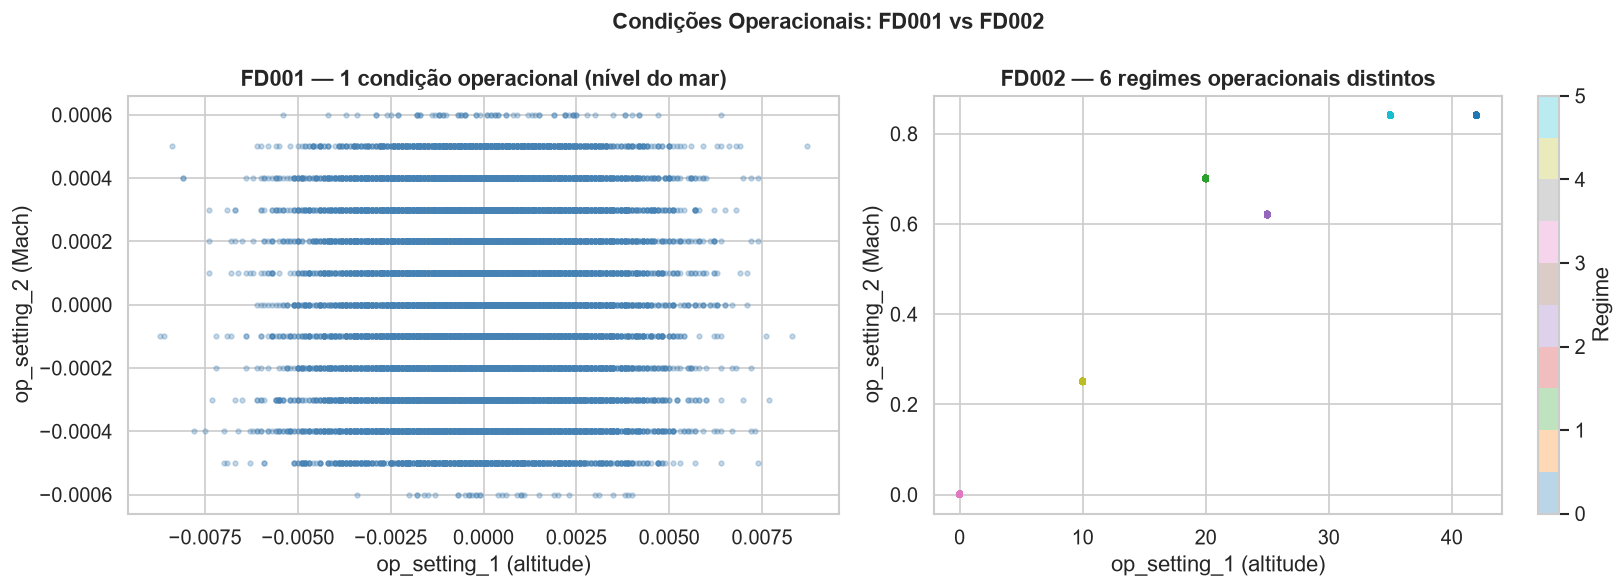

In [8]:
from sklearn.cluster import KMeans

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, subset in zip(axes, ["FD001", "FD002"]):
    train_sub = dados[subset]["train"]
    op_data = train_sub[["op_setting_1", "op_setting_2"]].values

    n_clusters = 1 if subset == "FD001" else 6
    if n_clusters > 1:
        kmeans = KMeans(n_clusters=n_clusters, random_state=42, n_init="auto")
        labels = kmeans.fit_predict(train_sub[COLUNAS_OP_SETTINGS].values)
        scatter = ax.scatter(op_data[:, 0], op_data[:, 1],
                             c=labels, cmap="tab10", alpha=0.3, s=8)
        plt.colorbar(scatter, ax=ax, label="Regime")
        ax.set_title(f"{subset} — 6 regimes operacionais distintos", fontweight="bold")
    else:
        ax.scatter(op_data[:, 0], op_data[:, 1],
                   color="steelblue", alpha=0.3, s=8)
        ax.set_title(f"{subset} — 1 condição operacional (nível do mar)", fontweight="bold")

    ax.set_xlabel("op_setting_1 (altitude)")
    ax.set_ylabel("op_setting_2 (Mach)")

fig.suptitle("Condições Operacionais: FD001 vs FD002", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

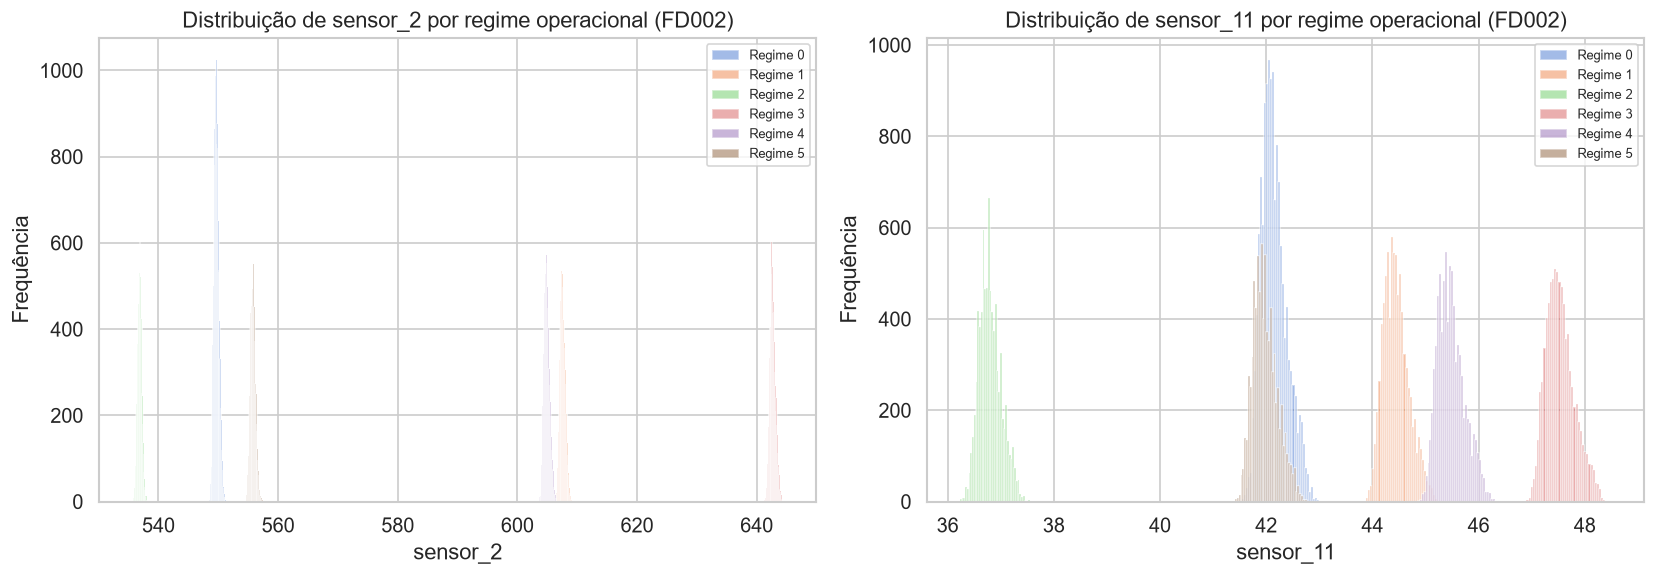

Amplitude por regime — sensor_2 (FD002):


,mean,std
regime,,
0,549.70,0.43
1,607.56,0.46
2,536.87,0.36
3,642.68,0.50
4,604.91,0.47
5,555.80,0.44


In [9]:
# Efeito do regime nos sensores — FD002
train_fd002 = dados["FD002"]["train"].copy()
kmeans = KMeans(n_clusters=6, random_state=42, n_init="auto")
train_fd002["regime"] = kmeans.fit_predict(train_fd002[COLUNAS_OP_SETTINGS].values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, sensor in zip(axes, ["sensor_2", "sensor_11"]):
    for regime in range(6):
        vals = train_fd002[train_fd002["regime"] == regime][sensor]
        ax.hist(vals, bins=40, alpha=0.5, label=f"Regime {regime}")
    ax.set_xlabel(f"{sensor}")
    ax.set_ylabel("Frequência")
    ax.set_title(f"Distribuição de {sensor} por regime operacional (FD002)")
    ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

print("Amplitude por regime — sensor_2 (FD002):")
train_fd002.groupby("regime")["sensor_2"].agg(["mean", "std"]).round(2)

> **Insight de negócio:** A diferença na leitura média do `sensor_2` entre regimes pode superar 100°R — muito maior do que o sinal de degradação (tipicamente alguns graus). **Sem normalizar por regime, o modelo aprende altitude, não degradação.** Por isso, na fase 02 aplicaremos z-score dentro de cada cluster operacional para FD002 e FD004.

## 8. Correlação entre Sensores Informativos

Sensores altamente correlacionados carregam informação redundante. Entender essa estrutura orienta a seleção de features e a interpretação do modelo.

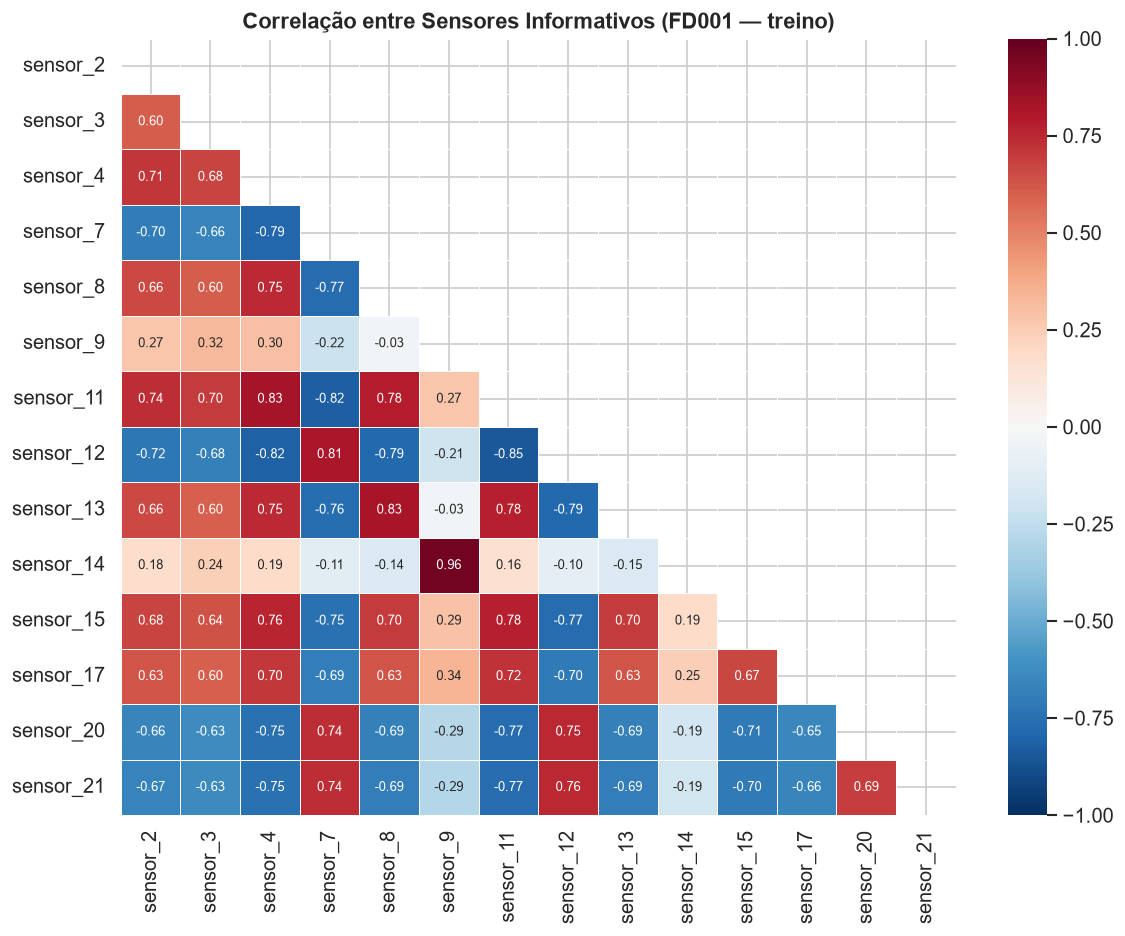

In [10]:
train_fd001 = dados["FD001"]["train"]
sensores_uteis = [c for c in COLUNAS_SENSORES if c not in constantes_nomes]

corr = train_fd001[sensores_uteis].corr()

fig, ax = plt.subplots(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(
    corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
    center=0, vmin=-1, vmax=1, linewidths=0.4,
    annot_kws={"size": 8}, ax=ax
)
ax.set_title("Correlação entre Sensores Informativos (FD001 — treino)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

## 8.1. Correlação Sensores × RUL

Antes de construir features, verificamos quais sensores têm correlação direta com o target (RUL). Isso valida a seleção de sensores informativos e antecipa a análise SHAP do Notebook 04.

Usamos **Spearman** (não Pearson) porque a relação sensor-RUL não é necessariamente linear e o RUL tem distribuição assimétrica após o cap de 125 ciclos.

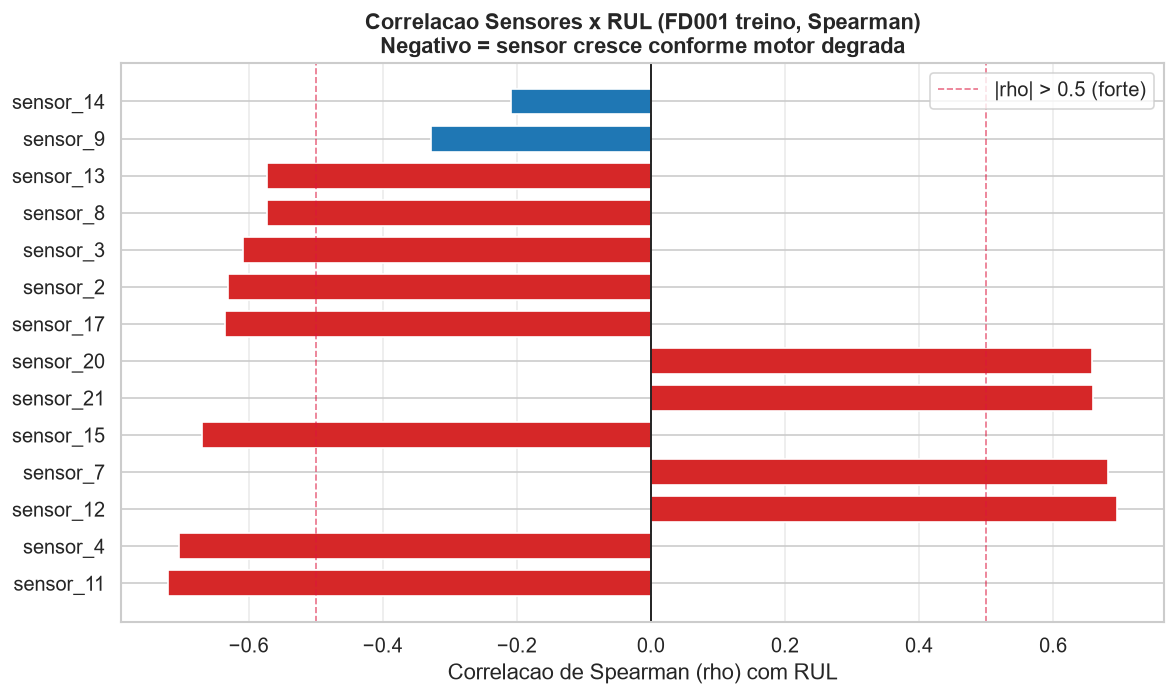

Sensores com correlacao forte (|rho| > 0.5) com o RUL:
              rho  p_value  sig
sensor_11 -0.7199      0.0  ***
sensor_4  -0.7045      0.0  ***
sensor_12  0.6954      0.0  ***
sensor_7   0.6824      0.0  ***
sensor_15 -0.6698      0.0  ***
sensor_21  0.6598      0.0  ***
sensor_20  0.6576      0.0  ***
sensor_17 -0.6353      0.0  ***
sensor_2  -0.6311      0.0  ***
sensor_3  -0.6087      0.0  ***
sensor_8  -0.5727      0.0  ***
sensor_13 -0.5723      0.0  ***


In [11]:
from scipy import stats as _stats

train_fd001_corr = dados["FD001"]["train"].copy()
max_c_corr = train_fd001_corr.groupby("unit_id")["cycle"].transform("max")
train_fd001_corr["rul"] = (max_c_corr - train_fd001_corr["cycle"]).clip(upper=RUL_CAP)

sensores_uteis_corr = [c for c in COLUNAS_SENSORES if c not in constantes_nomes]
corr_spearman = {}
for col in sensores_uteis_corr:
    r, p = _stats.spearmanr(train_fd001_corr[col], train_fd001_corr["rul"])
    corr_spearman[col] = {"rho": r, "p_value": p}

df_corr_rul = pd.DataFrame(corr_spearman).T.sort_values("rho", key=abs, ascending=False)
df_corr_rul["|rho|"] = df_corr_rul["rho"].abs()
df_corr_rul["sig"] = df_corr_rul["p_value"].apply(
    lambda p: "***" if p < 0.001 else ("**" if p < 0.01 else "*")
)

fig, ax = plt.subplots(figsize=(10, 6))
cores_corr = ["#d62728" if abs(r) > 0.5 else "#1f77b4" for r in df_corr_rul["rho"].values]
ax.barh(df_corr_rul.index, df_corr_rul["rho"].values, color=cores_corr, edgecolor="white", height=0.7)
ax.axvline(0, color="black", lw=1)
ax.axvline(0.5,  color="crimson", lw=1, linestyle="--", alpha=0.6, label="|rho| > 0.5 (forte)")
ax.axvline(-0.5, color="crimson", lw=1, linestyle="--", alpha=0.6)
ax.set_xlabel("Correlacao de Spearman (rho) com RUL")
ax.set_title(
    "Correlacao Sensores x RUL (FD001 treino, Spearman)\n"
    "Negativo = sensor cresce conforme motor degrada",
    fontweight="bold"
)
ax.legend()
ax.grid(axis="x", alpha=0.4)
plt.tight_layout()
plt.show()

print("Sensores com correlacao forte (|rho| > 0.5) com o RUL:")
print(df_corr_rul[df_corr_rul["|rho|"] > 0.5][["rho", "p_value", "sig"]].round(4).to_string())

## 9. RUL no Conjunto de Teste: O Que o Modelo Precisa Prever

No teste, o histórico do motor é **truncado** antes da falha. O arquivo `RUL_FD00X.txt` fornece o RUL verdadeiro no último ciclo observado. Essa é a grandeza que o modelo precisa prever.

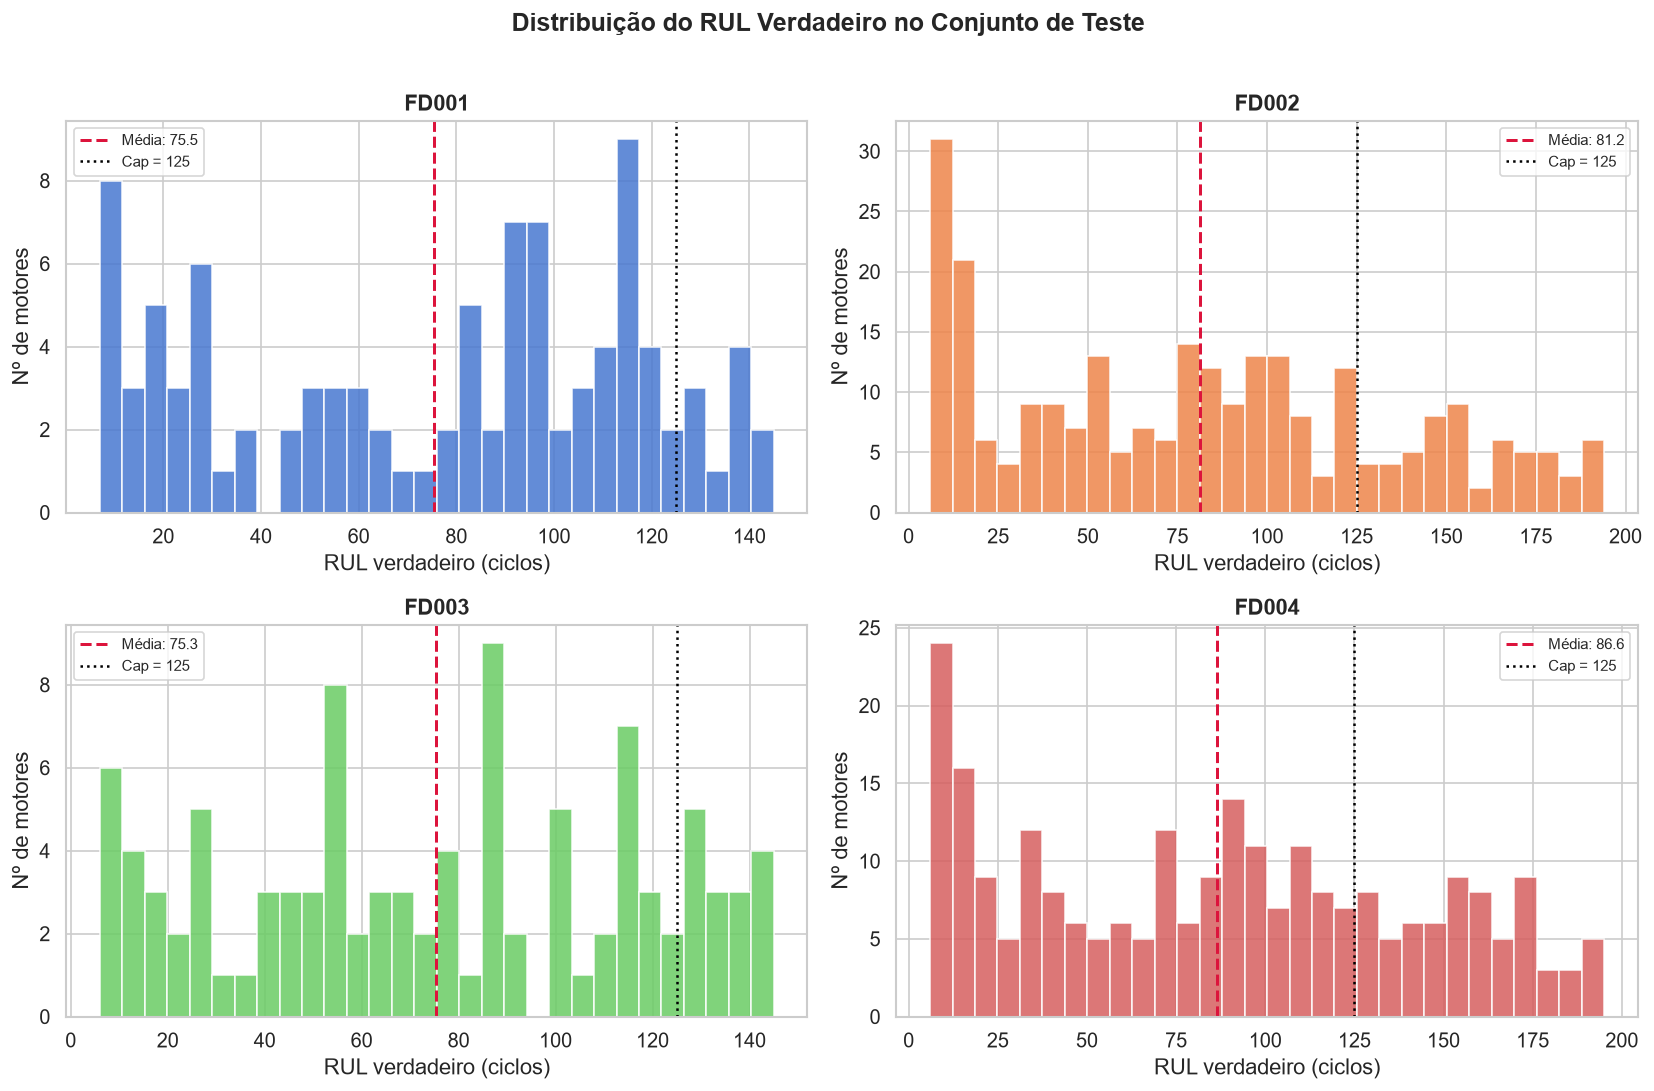

,Mín,Mediana,Média,Máx,% acima do cap
Subset,,,,,
FD001,7,86.0,75.5,145,11.0%
FD002,6,80.0,81.2,194,22.0%
FD003,6,77.5,75.3,145,15.0%
FD004,6,88.0,86.6,195,27.0%


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, subset in enumerate(SUBSETS):
    rul_test = dados[subset]["rul"]["rul"]
    ax = axes[i]
    ax.hist(rul_test, bins=30, color=sns.color_palette("muted")[i],
            edgecolor="white", alpha=0.85)
    ax.axvline(rul_test.mean(), color="crimson", linestyle="--", lw=1.8,
               label=f"Média: {rul_test.mean():.1f}")
    ax.axvline(RUL_CAP, color="black", linestyle=":", lw=1.5,
               label=f"Cap = {RUL_CAP}")
    ax.set_title(f"{subset}", fontsize=13, fontweight="bold")
    ax.set_xlabel("RUL verdadeiro (ciclos)")
    ax.set_ylabel("Nº de motores")
    ax.legend(fontsize=9)

fig.suptitle("Distribuição do RUL Verdadeiro no Conjunto de Teste",
             fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout()
plt.show()

# Estatísticas
stats_rul_test = []
for subset in SUBSETS:
    rul = dados[subset]["rul"]["rul"]
    stats_rul_test.append({
        "Subset": subset,
        "Mín": rul.min(),
        "Mediana": rul.median(),
        "Média": round(rul.mean(), 1),
        "Máx": rul.max(),
        "% acima do cap": f"{(rul > RUL_CAP).mean() * 100:.1f}%",
    })
pd.DataFrame(stats_rul_test).set_index("Subset")

## 10. Assimetria do Erro: O Custo de Errar para Mais vs para Menos

Na manutenção preditiva, errar o RUL não tem custo simétrico:

| Tipo de erro | Situação | Consequência |
|---|---|---|
| **Subestimar RUL** (prever menos do que real) | Motor tem mais vida do que previsto | Manutenção prematura — custo desnecessário |
| **Superestimar RUL** (prever mais do que real) | Motor tem menos vida do que previsto | **Falha em operação — custo catastrófico** |

O **PHM Score (Saxena 2008)** captura essa assimetria: penaliza previsões tardias (superestimar RUL) **exponencialmente mais** do que previsões adiantadas.

$$s_i = \begin{cases} e^{-d/13} - 1 & \text{se } d < 0 \text{ (adiantado)} \\ e^{d/10} - 1 & \text{se } d \geq 0 \text{ (atrasado)} \end{cases}$$

onde $d = \hat{y} - y$ (predito menos real).

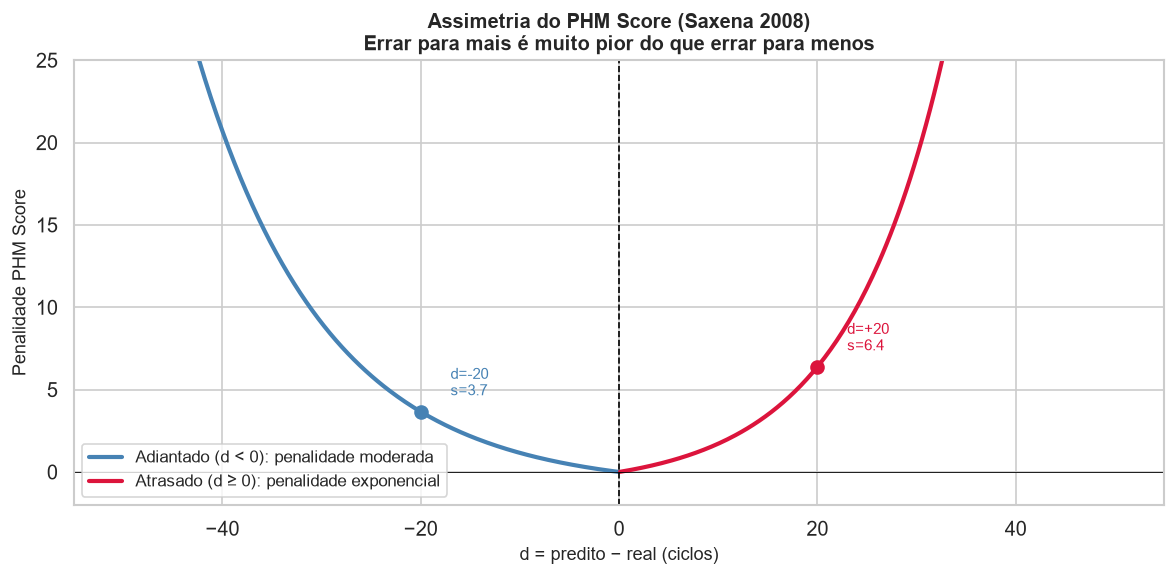

Comparativo PHM Score (3 motores, RUL real = 50 ciclos cada):
  Perfeito (d=0)                      → PHM Score = 0.00
  Adiantado em 10 (d=-10)             → PHM Score = 3.47
  Atrasado em 10 (d=+10)              → PHM Score = 5.15


In [13]:
from src.evaluation.metrics import phm_score

# Visualiza a assimetria do PHM Score
d_range = np.linspace(-50, 50, 500)
score_vals = np.where(
    d_range < 0,
    np.exp(-d_range / 13.0) - 1.0,
    np.exp(d_range / 10.0) - 1.0,
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(d_range[d_range < 0], score_vals[d_range < 0],
        color="steelblue", lw=2.5, label="Adiantado (d < 0): penalidade moderada")
ax.plot(d_range[d_range >= 0], score_vals[d_range >= 0],
        color="crimson", lw=2.5, label="Atrasado (d ≥ 0): penalidade exponencial")
ax.axvline(0, color="black", linestyle="--", lw=1)
ax.axhline(0, color="black", linestyle="-", lw=0.5)

# Anota exemplos
for d_ex, cor in [(-20, "steelblue"), (20, "crimson")]:
    s_ex = np.exp(-d_ex / 13.0) - 1.0 if d_ex < 0 else np.exp(d_ex / 10.0) - 1.0
    ax.annotate(f"d={d_ex:+d}\ns={s_ex:.1f}",
                xy=(d_ex, s_ex), xytext=(d_ex + 3, s_ex + 1),
                fontsize=9, color=cor)
    ax.scatter([d_ex], [s_ex], color=cor, zorder=5, s=60)

ax.set_xlabel("d = predito − real (ciclos)", fontsize=11)
ax.set_ylabel("Penalidade PHM Score", fontsize=11)
ax.set_title("Assimetria do PHM Score (Saxena 2008)\nErrar para mais é muito pior do que errar para menos",
             fontsize=12, fontweight="bold")
ax.legend(fontsize=10)
ax.set_ylim(-2, 25)
plt.tight_layout()
plt.show()

# Exemplo numérico
y_real = [50, 50, 50]
cenarios = {
    "Perfeito (d=0)": [50, 50, 50],
    "Adiantado em 10 (d=-10)": [40, 40, 40],
    "Atrasado em 10 (d=+10)": [60, 60, 60],
}
print("Comparativo PHM Score (3 motores, RUL real = 50 ciclos cada):")
for nome, y_pred in cenarios.items():
    s = phm_score(y_real, y_pred)
    print(f"  {nome:35s} → PHM Score = {s:.2f}")

## 11. Síntese: O Que o Modelo Precisa Aprender

Com a EDA concluída, podemos formular o problema com precisão:

### Dados disponíveis no momento da previsão
- Histórico completo de leituras de sensores até o ciclo atual
- Condições operacionais de cada ciclo
- **Não** sabemos a vida útil total do motor (é o que queremos prever)

### Desafios identificados

| Desafio | Impacto | Solução planejada (Fase 02) |
|---|---|---|
| Ruído nos sensores | Dificulta captura de tendência | Rolling features (média, std, slope) |
| 7 sensores constantes | Features inúteis aumentam dimensionalidade | Remoção na pipeline |
| Múltiplos regimes (FD002/4) | Confunde nível de operação com degradação | Normalização por regime (KMeans) |
| Fase inicial sem sinal | Aprender ruído nos primeiros ciclos | Piecewise RUL cap (125 ciclos) |
| Custo assimétrico de erro | RMSE não é suficiente | PHM Score como métrica adicional |

### Features planejadas (Fase 02)
Para cada sensor informativo, calcular em janela de 30 ciclos:
- `sensor_X_mean_30` — nível atual suavizado
- `sensor_X_std_30` — variabilidade (instabilidade = degradação?)
- `sensor_X_slope_30` — taxa de mudança
- `sensor_X_min_30`, `sensor_X_max_30` — valores extremos
- `sensor_X_delta_baseline` — desvio do estado inicial (quanto o sensor mudou desde o início)

In [14]:
# Resumo quantitativo final
print("=" * 60)
print("RESUMO DA EDA")
print("=" * 60)

total_motores_treino = sum(dados[s]["train"]["unit_id"].nunique() for s in SUBSETS)
total_linhas_treino = sum(len(dados[s]["train"]) for s in SUBSETS)

print(f"\nDataset C-MAPSS (todos os subsets):")
print(f"  Motores no treino (total): {total_motores_treino}")
print(f"  Observações de treino:     {total_linhas_treino:,} ciclos")
print(f"  Variáveis brutas:          26 (unit_id, cycle, 3 op_settings, 21 sensores)")
print(f"  Sensores constantes:       {len(SENSORES_CONSTANTES)} → remover")
print(f"  Sensores informativos:     {21 - len(SENSORES_CONSTANTES)} → usar")

print(f"\nTarget (RUL):")
print(f"  Cap piecewise:             {RUL_CAP} ciclos")
print(f"  Subsets com multi-regime:  FD002 e FD004 (6 condições operacionais)")

n_features_esperadas = (21 - len(SENSORES_CONSTANTES)) * 6
print(f"\nFeatures esperadas (Fase 02):")
print(f"  {21 - len(SENSORES_CONSTANTES)} sensores × 6 estatísticas = {n_features_esperadas} features rolling")
print(f"  + 3 op_settings originais")
print(f"  Total estimado: ~{n_features_esperadas + 3} features")

RESUMO DA EDA

Dataset C-MAPSS (todos os subsets):
  Motores no treino (total): 709
  Observações de treino:     160,359 ciclos
  Variáveis brutas:          26 (unit_id, cycle, 3 op_settings, 21 sensores)
  Sensores constantes:       7 → remover
  Sensores informativos:     14 → usar

Target (RUL):
  Cap piecewise:             125 ciclos
  Subsets com multi-regime:  FD002 e FD004 (6 condições operacionais)

Features esperadas (Fase 02):
  14 sensores × 6 estatísticas = 84 features rolling
  + 3 op_settings originais
  Total estimado: ~87 features


---

## Próximos Passos

**Fase 02 — Feature Engineering** (`notebooks/02_features/`):
1. Implementar `rolling_features()` em `src/features/rolling.py`
2. Implementar `RegimeNormalizer` em `src/features/normalization.py`
3. Gerar `data/processed/train_FD00X.parquet` e `test_FD00X.parquet`

**Fase 03 — Modelagem** (`notebooks/03_modeling/`):
1. Ridge Regression como baseline
2. Random Forest, XGBoost, LightGBM
3. Stacking ensemble
4. Tuning com Optuna (100 trials/modelo)

---
*Referência principal: Saxena, A. et al. (2008). "Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation." PHM Society Conference.*

---
## 12. Equivalência Operacional — Traduzindo Erro em Custo

Para a decisão de negócio, o RMSE precisa ser traduzido em impacto operacional concreto. Aqui estabelecemos a régua que será usada para avaliar os modelos na Fase 04.

**Premissas (conservadoras, para referência de ordem de grandeza):**
- 1 ciclo ≈ 10 horas de voo (voo doméstico médio)
- Custo AOG (Aircraft on Ground): US$ 50.000/hora (ponto médio do range US$ 10k–150k)
- Manutenção preventiva: US$ 50.000/evento | Manutenção corretiva: US$ 200.000/evento

In [15]:
HORAS_POR_CICLO   = 10
CUSTO_AOG_HORA    = 50_000

cenarios = {
    "Objetivo (XGBoost esperado)": 12.5,
    "Aceitavel (benchmark lit.)": 15.0,
    "Baseline linear (Ridge)": 18.6,
}

print("=" * 70)
print("EQUIVALENCIA OPERACIONAL  |  1 ciclo = 10h de voo")
print("=" * 70)
print(f"{'Cenario':<35s} {'RMSE':>6s} {'Incerteza (h)':>14s} {'Risco/evento*':>14s}")
print("-" * 72)
for nome, rmse_val in cenarios.items():
    horas = rmse_val * HORAS_POR_CICLO
    risco = (rmse_val / 2) * HORAS_POR_CICLO * CUSTO_AOG_HORA / 1_000
    print(f"{nome:<35s} {rmse_val:>6.1f} {horas:>14.0f} US${risco:>11.0f}k")

print("\n* Risco/evento = (RMSE/2) ciclos x horas/ciclo x custo AOG/hora")
print("  Interpretacao: custo esperado de imprecisao por evento de manutencao")
print()
ganho_ciclos = cenarios["Baseline linear (Ridge)"] - cenarios["Objetivo (XGBoost esperado)"]
ganho_horas  = ganho_ciclos * HORAS_POR_CICLO
ganho_custo  = (ganho_ciclos / 2) * HORAS_POR_CICLO * CUSTO_AOG_HORA / 1_000
print(f"Ganho Ridge -> XGBoost: {ganho_ciclos:.1f} ciclos = {ganho_horas:.0f}h = "
      f"~US${ganho_custo:.0f}k economizados por evento de manutencao")
print("(Nota: valores ilustrativos para audiencia de MBA.")
print(" Dados reais variam por operadora, rota e configuracao de frota.)")

EQUIVALENCIA OPERACIONAL  |  1 ciclo = 10h de voo
Cenario                               RMSE  Incerteza (h)  Risco/evento*
------------------------------------------------------------------------
Objetivo (XGBoost esperado)           12.5            125 US$       3125k
Aceitavel (benchmark lit.)            15.0            150 US$       3750k
Baseline linear (Ridge)               18.6            186 US$       4650k

* Risco/evento = (RMSE/2) ciclos x horas/ciclo x custo AOG/hora
  Interpretacao: custo esperado de imprecisao por evento de manutencao

Ganho Ridge -> XGBoost: 6.1 ciclos = 61h = ~US$1525k economizados por evento de manutencao
(Nota: valores ilustrativos para audiencia de MBA.
 Dados reais variam por operadora, rota e configuracao de frota.)
